# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Delos Santos, Mico
- _Student No._: 2024-35117
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

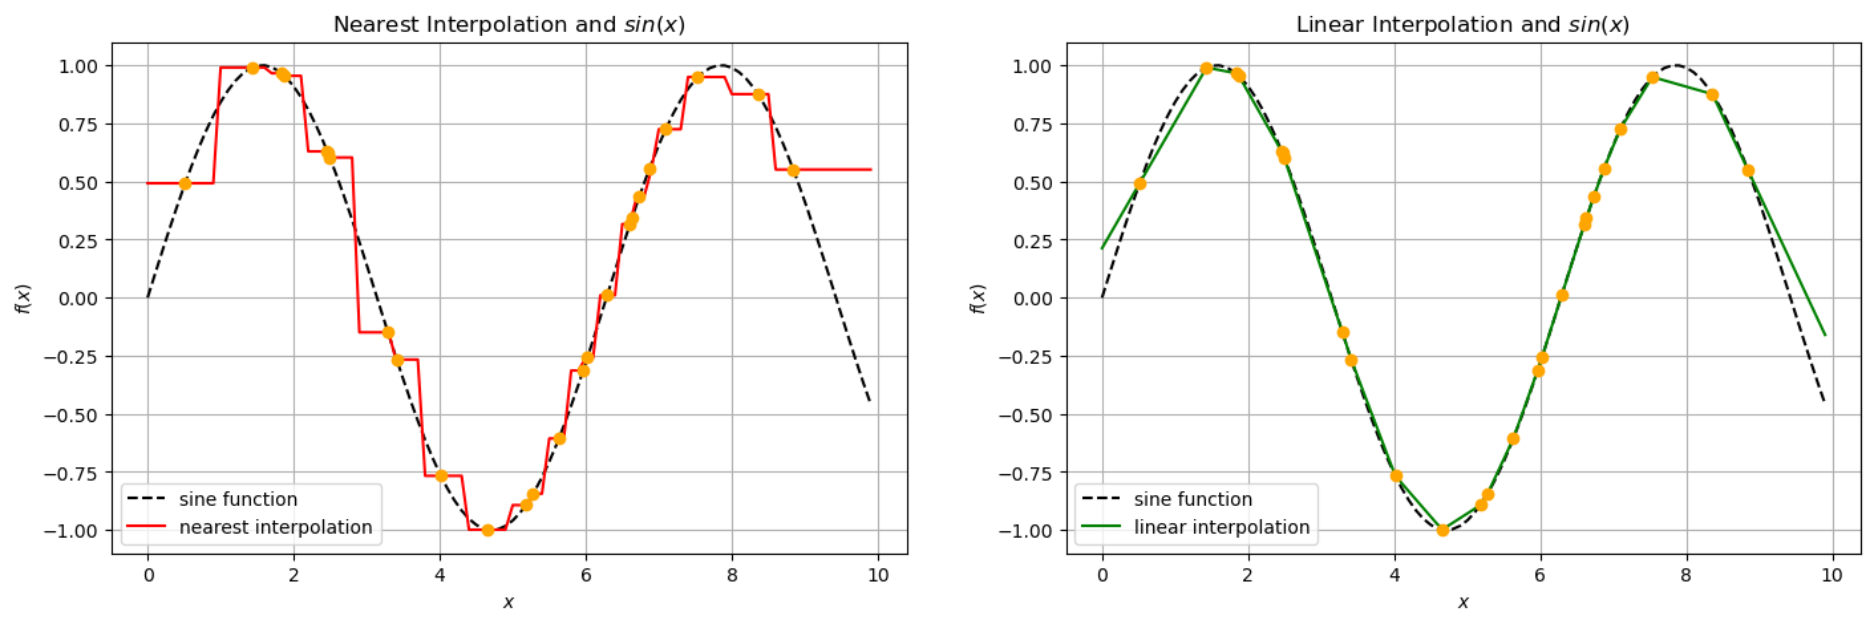
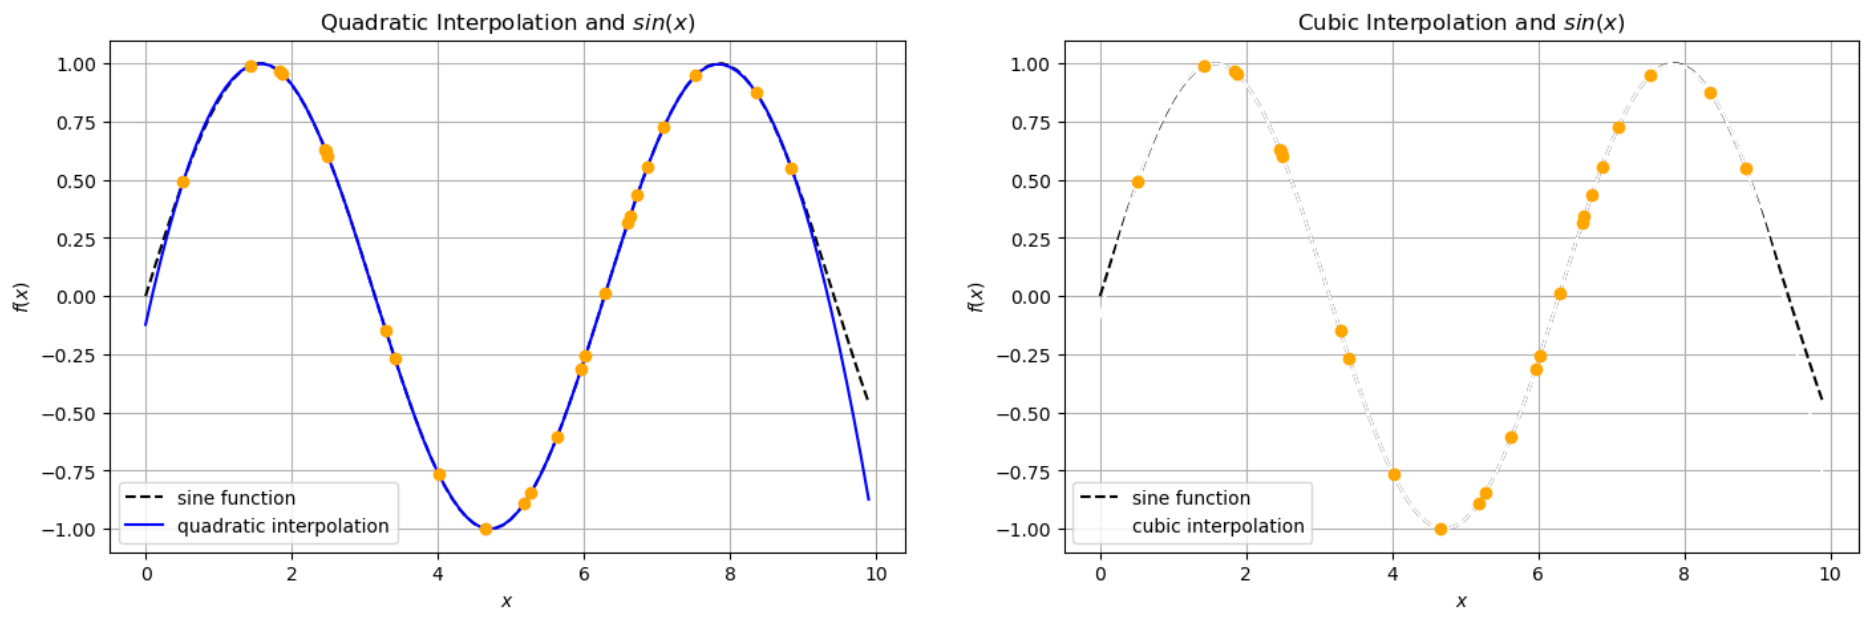
**Figure 1. Synthetic data interpolation**

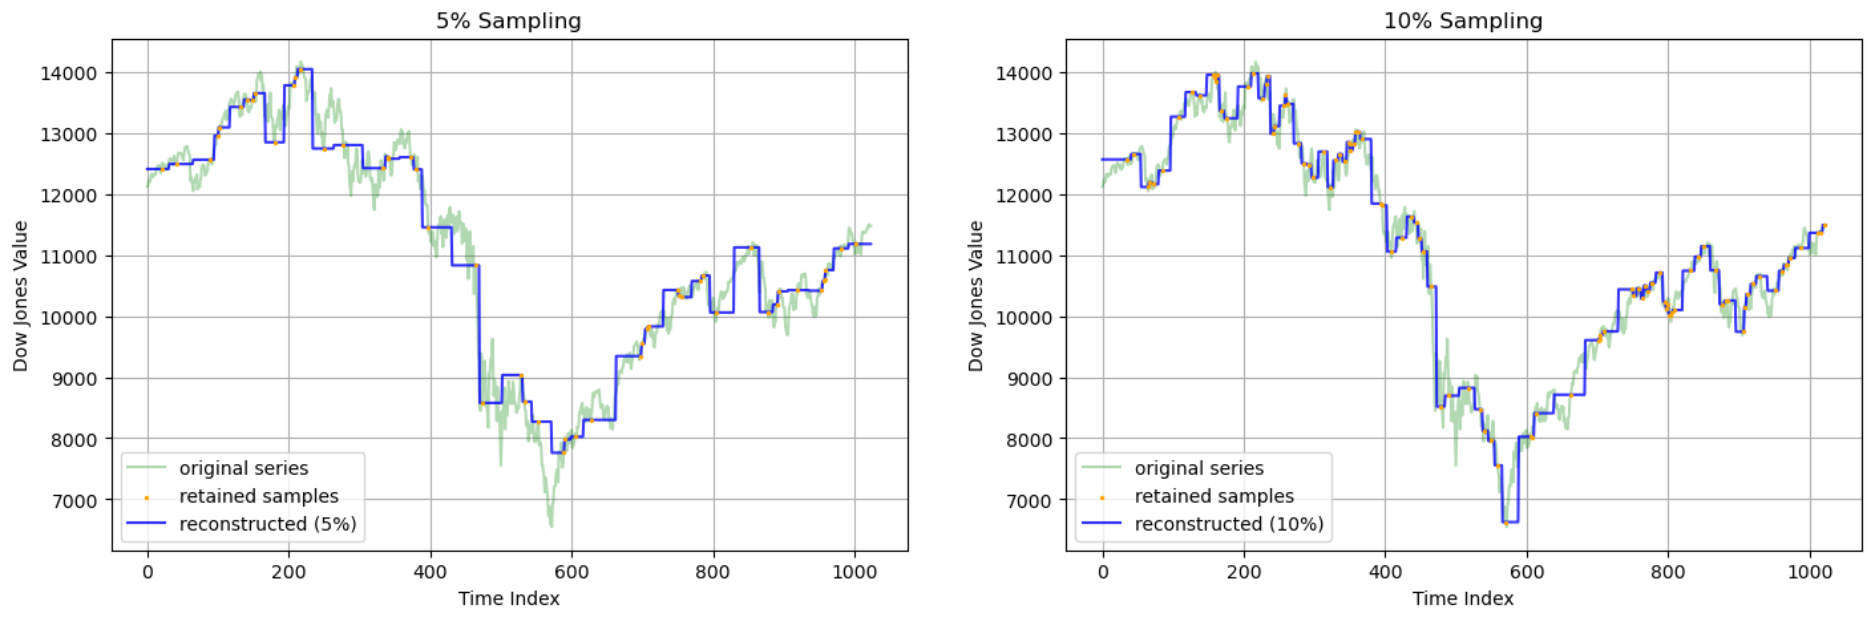
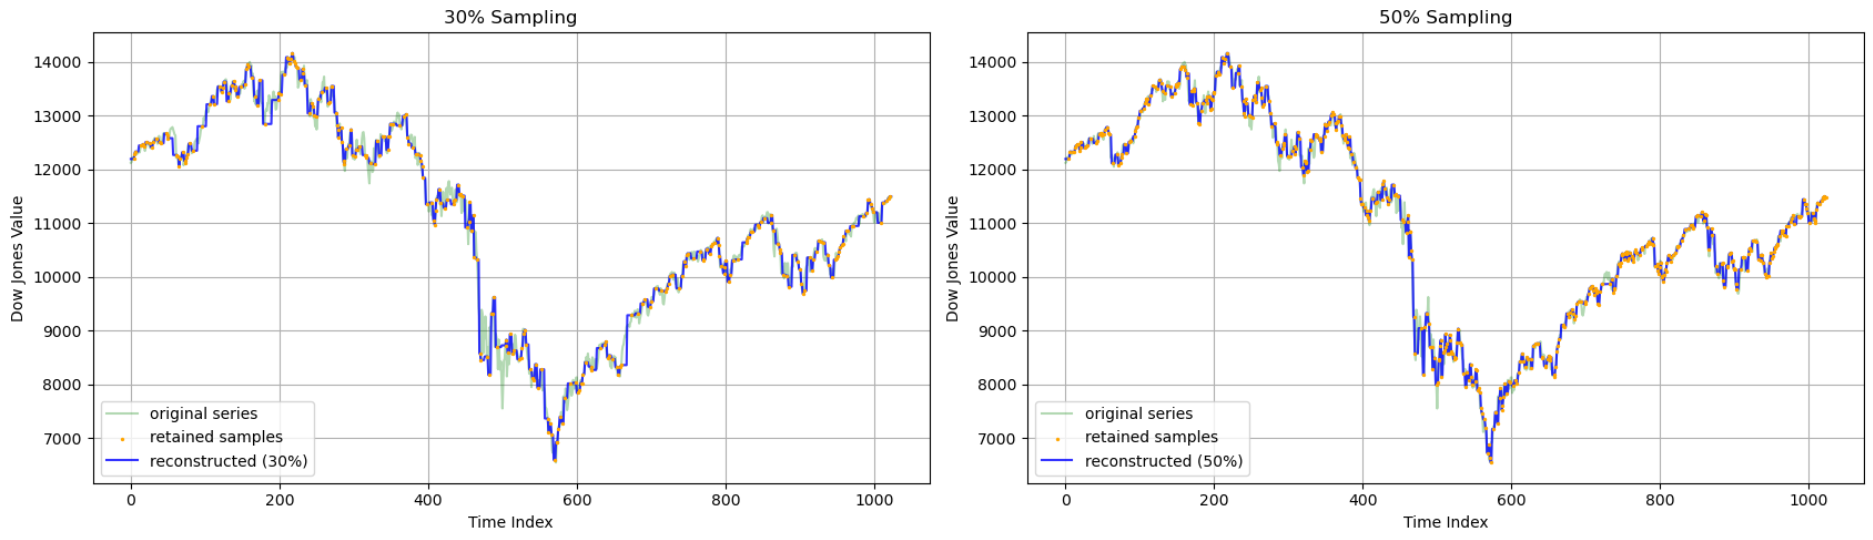
**Figure 2. Real-world data reconstruction**

### Report discussion

**Interpolator comparison:**
As seen from Figure 1., the nearest interpolation is the accurate among the interpolation. It's also the most 'box'-looking type of interpolation, very rigid when compared with the other. It does not cover the function $sin(x)$ completely, and very visible. For linear interpolation, we now have lines covering mosty the function $sin(x)$. A good improvement from the previous one.

A quadratic interpolation should be the 'standard' interpolation. It covers the middle interval of the function but becomes distant in the initial and final points of the function. A similar description can be said to cubic interpolation, a slight improments from previous interpolation method. Both these methods are smoother to look at and very accurate compared to the first two interpolation methods.

**Sampling-level comparison:**
As seen from Figure 2., the more sampling fractions, the greater it connects the random points in the graph. I chose the nearest interpolation for this one it's because they are cool, I would say so.
For 5% sampling, the original green series is very much visible , and does not capture the spikes of the series. For the 10% sampling, we see an improvements, it now capture the spikes, but the series is still visible. For 30% sampling, we now see the random points in the series, in which also covers those small spikes (or changes in the series). Lastly, the best sampling fraction is the 50%. The original series in green is still visible, but was able to minimize by the random points in color gold. It is also less 'boxy' in texture and is actually having spikes.

### Other comments
- Sorry sir, my submission of this activity is late. We do not have an internet connection (globe) for the whole Friday, and until the afternoon of Saturday.

---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path
import random

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

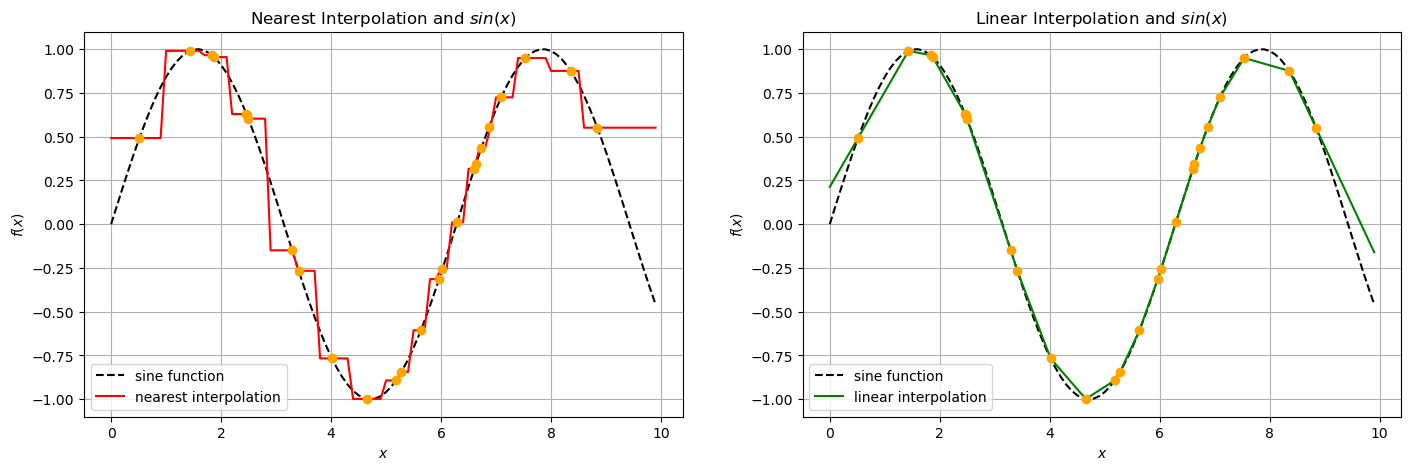

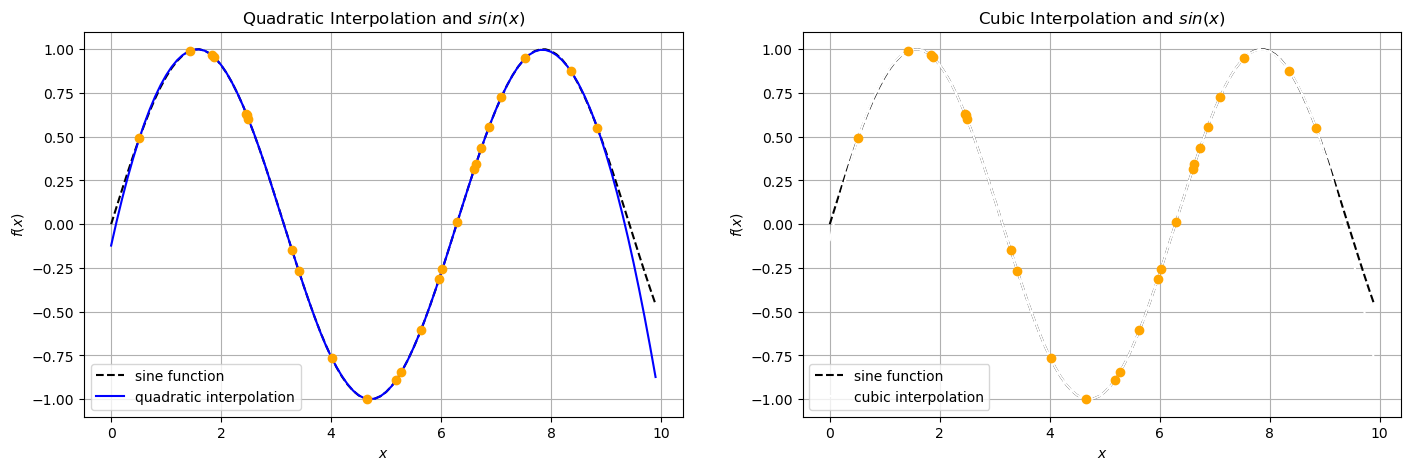

In [27]:
x = np.arange(0, 10, 0.1)
y = np.sin(x)
x_sample = np.random.uniform(0, 10, size=25)
y_sample = np.sin(x_sample)

f_linear = interpolate.interp1d(x_sample, y_sample, kind='linear', bounds_error=False, fill_value="extrapolate")
f_cubic = interpolate.interp1d(x_sample, y_sample, kind='cubic', bounds_error=False, fill_value="extrapolate")
f_nearest = interpolate.interp1d(x_sample, y_sample, kind='nearest', bounds_error=False, fill_value="extrapolate")
f_quadratic = interpolate.interp1d(x_sample, y_sample, kind='quadratic', bounds_error=False, fill_value="extrapolate")

fig, axs = plt.subplots(1, 2, figsize=(17,5))

axs[0].plot(x, y, "--", label="sine function", color="black")
axs[0].scatter(x_sample, y_sample, color="orange", zorder=5)
axs[0].plot(x, f_nearest(x), "-", label="nearest interpolation", color="red")
axs[0].set_title('Nearest Interpolation and $sin(x)$')
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$f(x)$')
axs[0].grid()
axs[0].legend()

axs[1].plot(x, y, "--", label="sine function", color="black")
axs[1].scatter(x_sample, y_sample, color="orange", zorder=5) 
axs[1].plot(x, f_linear(x), "-", label="linear interpolation", color="green")
axs[1].set_title('Linear Interpolation and $sin(x)$')
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$f(x)$')
axs[1].grid()
axs[1].legend()

fig, axs = plt.subplots(1, 2, figsize=(17,5))

axs[0].plot(x, y, "--", label="sine function", color="black")
axs[0].scatter(x_sample, y_sample, color="orange", zorder=5)
axs[0].plot(x, f_quadratic(x), "-", label="quadratic interpolation", color="blue")
axs[0].set_title('Quadratic Interpolation and $sin(x)$')
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$f(x)$')
axs[0].grid()
axs[0].legend()

axs[1].plot(x, y, "--", label="sine function", color="black")
axs[1].scatter(x_sample, y_sample, color="orange", zorder=5)
axs[1].plot(x, f_cubic(x), "-", label="cubic interpolation", color="white")
axs[1].set_title('Cubic Interpolation and $sin(x)$')
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$f(x)$')
axs[1].grid()
axs[1].legend()

plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [63]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [62]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

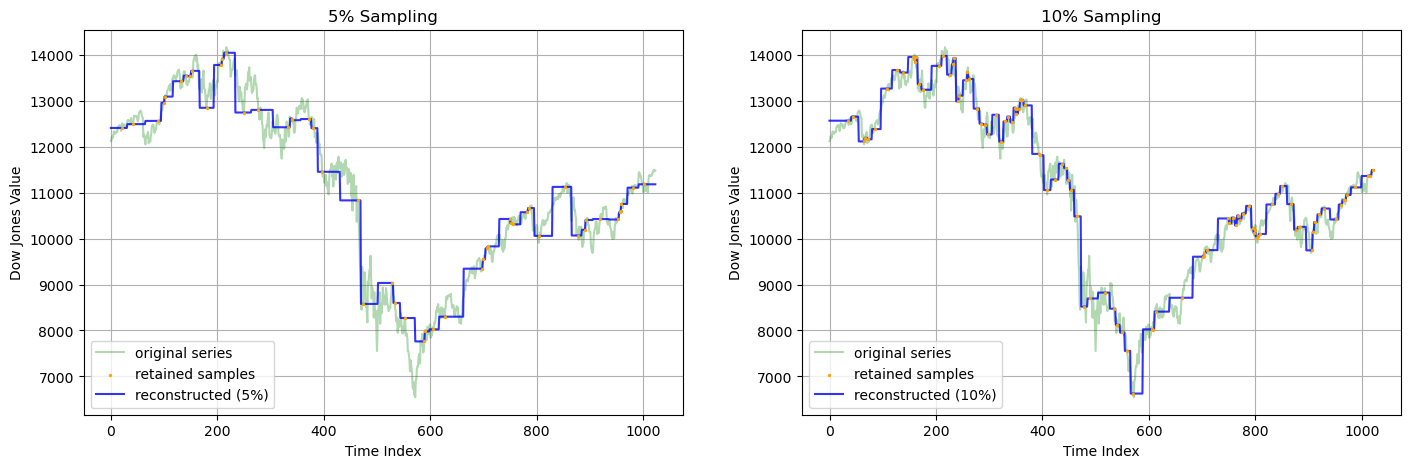

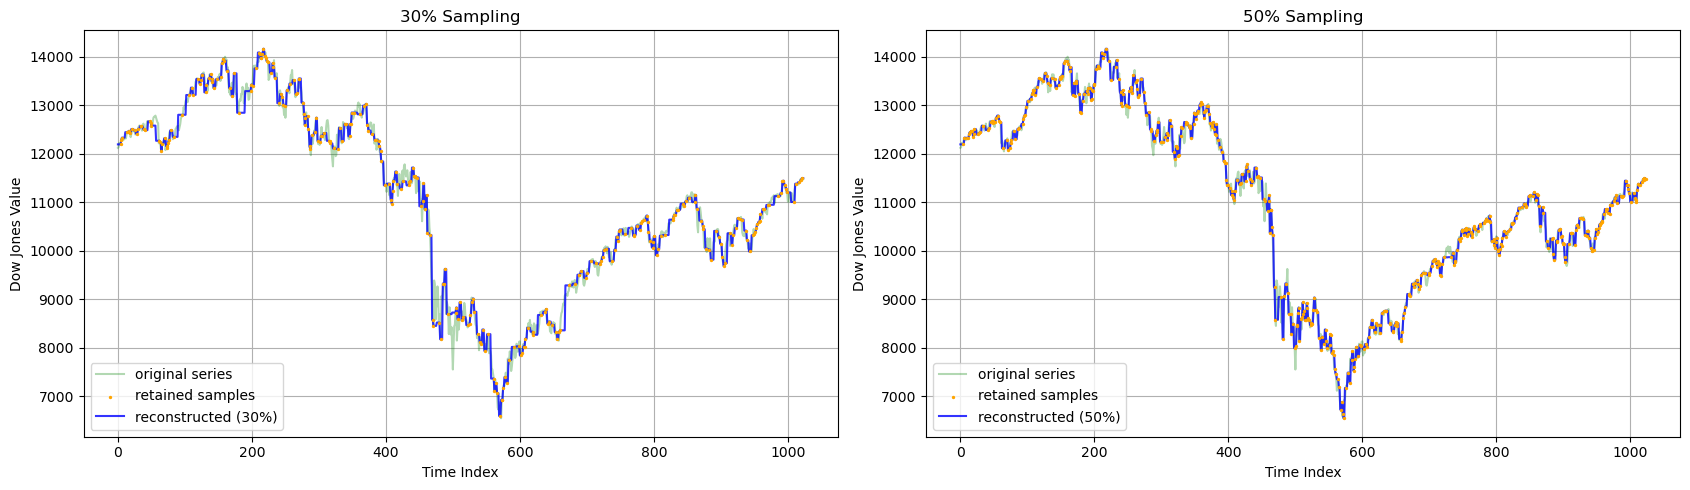

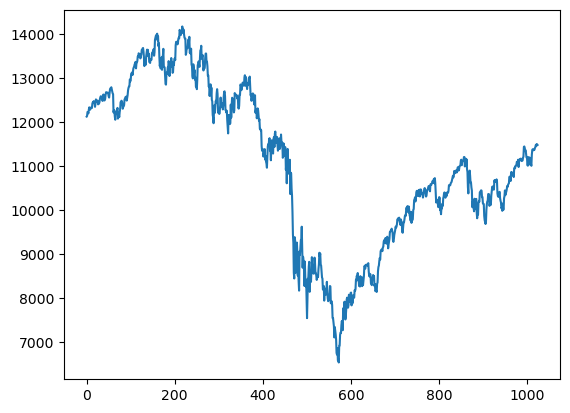

In [28]:
dow = np.loadtxt("dow.txt")

x = np.arange(len(dow))
y = dow

#sampling for each fractions
x_50 = np.sort(np.random.choice(len(dow), size=int(len(dow) * 0.5), replace=False))
x_30 = np.sort(np.random.choice(len(dow), size=int(len(dow) * 0.3), replace=False))
x_10 = np.sort(np.random.choice(len(dow), size=int(len(dow) * 0.1), replace=False))
x_05 = np.sort(np.random.choice(len(dow), size=int(len(dow) * 0.05), replace=False))

y_50 = y[x_50]
y_30 = y[x_30]
y_10 = y[x_10]
y_05 = y[x_05]

#types of interpolation
f_50 = interpolate.interp1d(x_50, y_50, kind='nearest', bounds_error=False, fill_value="extrapolate")
f_30 = interpolate.interp1d(x_30, y_30, kind='nearest', bounds_error=False, fill_value="extrapolate")
f_10 = interpolate.interp1d(x_10, y_10, kind='nearest', bounds_error=False, fill_value="extrapolate")
f_05 = interpolate.interp1d(x_05, y_05, kind='nearest', bounds_error=False, fill_value="extrapolate")

fig, axs = plt.subplots(1, 2, figsize=(17, 5))

axs[0].plot(x, y, color="green", alpha=0.3, label="original series")
axs[0].scatter(x_05, y_05, color="orange", s=2, zorder=5, label="retained samples")
axs[0].plot(x, f_05(x), color="blue", alpha=0.8, label="reconstructed (5%)")
axs[0].set_title("5% Sampling")
axs[0].set_xlabel("Time Index")
axs[0].set_ylabel("Dow Jones Value")
axs[0].grid()
axs[0].legend(loc="lower left")

axs[1].plot(x, y, color="green", alpha=0.3, label="original series")
axs[1].scatter(x_10, y_10, color="orange", s=2, zorder=5, label="retained samples")
axs[1].plot(x, f_10(x), color="blue", alpha=0.8, label="reconstructed (10%)")
axs[1].set_title("10% Sampling")
axs[1].set_xlabel("Time Index")
axs[1].set_ylabel("Dow Jones Value")
axs[1].grid()
axs[1].legend(loc="lower left")

fig, axs = plt.subplots(1, 2, figsize=(17, 5))

axs[0].plot(x, y, color="green", alpha=0.3, label="original series")
axs[0].scatter(x_30, y_30, color="orange", s=2, zorder=5, label="retained samples")
axs[0].plot(x, f_30(x), color="blue", alpha=0.8, label="reconstructed (30%)")
axs[0].set_title("30% Sampling")
axs[0].set_xlabel("Time Index")
axs[0].set_ylabel("Dow Jones Value")
axs[0].grid()
axs[0].legend(loc="lower left")

axs[1].plot(x, y, color="green", alpha=0.3, label="original series")
axs[1].scatter(x_50, y_50, color="orange", s=2, zorder=5, label="retained samples")
axs[1].plot(x, f_50(x), color="blue", alpha=0.8, label="reconstructed (50%)")
axs[1].set_title("50% Sampling")
axs[1].set_xlabel("Time Index")
axs[1].set_ylabel("Dow Jones Value")
axs[1].grid()
axs[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

plt.plot(dow)

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

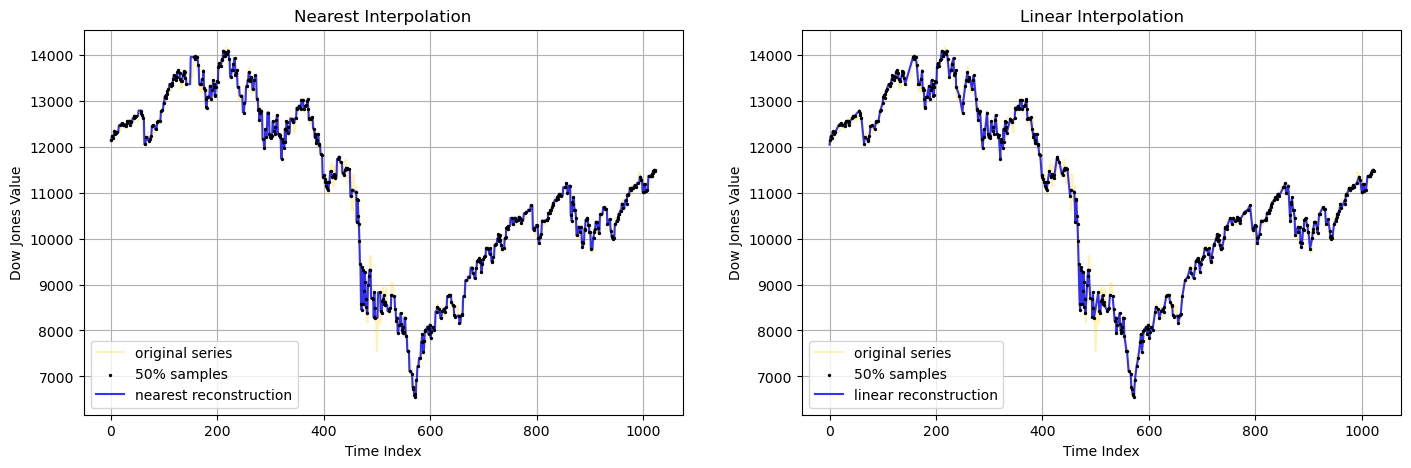

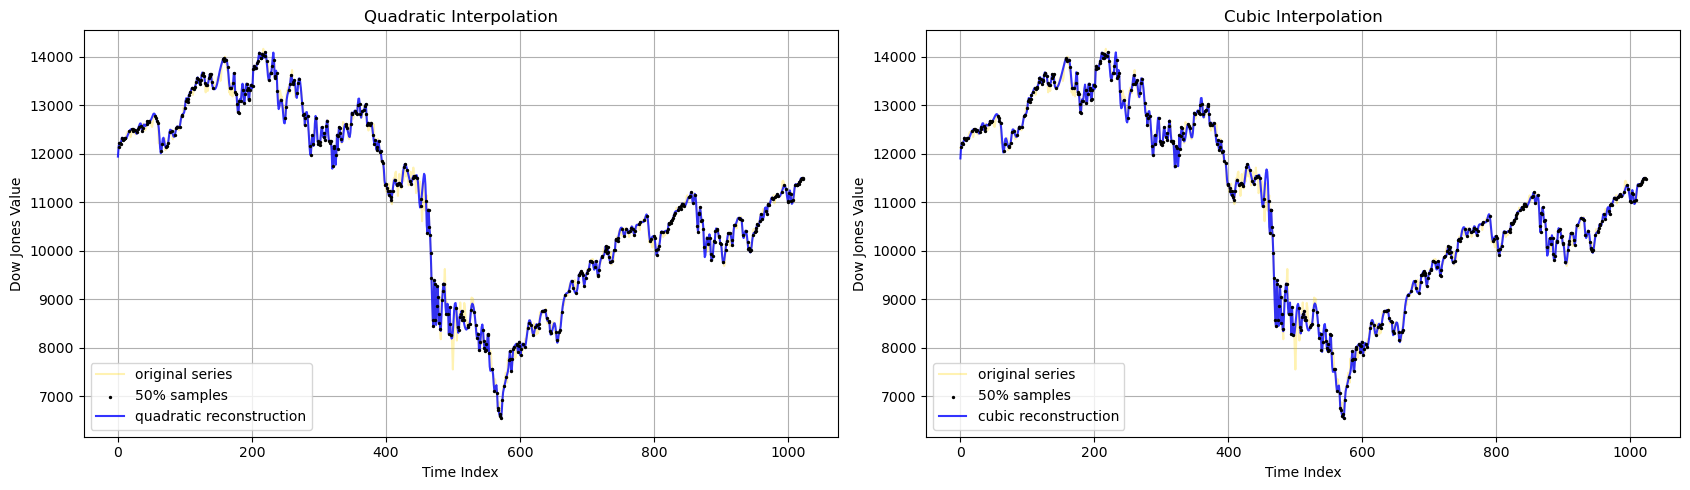

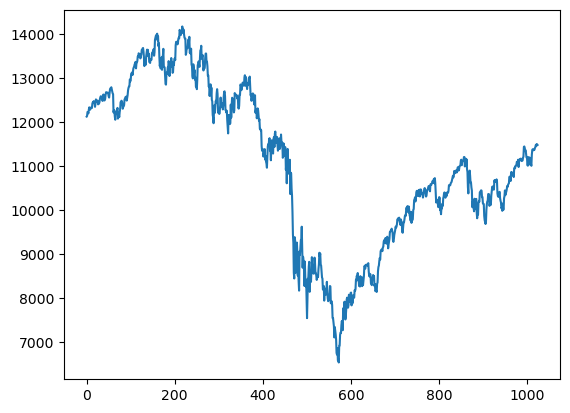

In [29]:
dow = np.loadtxt("dow.txt")

x = np.arange(len(dow))
y = dow

#sampling 
x_50 = np.sort(np.random.choice(len(dow), size=int(len(dow) * 0.5), replace=False))
y_50 = y[x_50]

#types of interpolation
near_50 = interpolate.interp1d(x_50, y_50, kind='nearest', bounds_error=False, fill_value="extrapolate")
lin_50 = interpolate.interp1d(x_50, y_50, kind='linear', bounds_error=False, fill_value="extrapolate")
quad_50 = interpolate.interp1d(x_50, y_50, kind='quadratic', bounds_error=False, fill_value="extrapolate")
cub_50 = interpolate.interp1d(x_50, y_50, kind='cubic', bounds_error=False, fill_value="extrapolate")

fig, axs = plt.subplots(1, 2, figsize=(17, 5))

axs[0].plot(x, y, color="gold", alpha=0.3, label="original series")
axs[0].scatter(x_50, y_50, color="black", s=2, zorder=5, label="50% samples")
axs[0].plot(x, near_50(x), color="blue", alpha=0.8, label="nearest reconstruction")
axs[0].set_title("Nearest Interpolation")
axs[0].set_xlabel("Time Index")
axs[0].set_ylabel("Dow Jones Value")
axs[0].grid()
axs[0].legend(loc="lower left")

axs[1].plot(x, y, color="gold", alpha=0.3, label="original series")
axs[1].scatter(x_50, y_50, color="black", s=2, zorder=5, label="50% samples")
axs[1].plot(x, lin_50(x), color="blue", alpha=0.8, label="linear reconstruction")
axs[1].set_title("Linear Interpolation")
axs[1].set_xlabel("Time Index")
axs[1].set_ylabel("Dow Jones Value")
axs[1].grid()
axs[1].legend(loc="lower left")

fig, axs = plt.subplots(1, 2, figsize=(17, 5))

axs[0].plot(x, y, color="gold", alpha=0.3, label="original series")
axs[0].scatter(x_50, y_50, color="black", s=2, zorder=5, label="50% samples")
axs[0].plot(x, quad_50(x), color="blue", alpha=0.8, label="quadratic reconstruction")
axs[0].set_title("Quadratic Interpolation")
axs[0].set_xlabel("Time Index")
axs[0].set_ylabel("Dow Jones Value")
axs[0].grid()
axs[0].legend(loc="lower left")

axs[1].plot(x, y, color="gold", alpha=0.3, label="original series")
axs[1].scatter(x_50, y_50, color="black", s=2, zorder=5, label="50% samples")
axs[1].plot(x, cub_50(x), color="blue", alpha=0.8, label="cubic reconstruction")
axs[1].set_title("Cubic Interpolation")
axs[1].set_xlabel("Time Index")
axs[1].set_ylabel("Dow Jones Value")
axs[1].grid()
axs[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

plt.plot(dow)

### Problem  code summary

The structure of the code is the same so that it's recognizable and readable even after forgetting everything that happened here. There's also a color coding in here so that it's recognizable.

---